**Задача 1**

1. Проверка гипотезы без АБ
На Учи.Ру есть механика "Марафон": дети в классе должны решить за месяц как можно больше заданий, классы соревнуются друг с другом. Механика побуждает детей решать больше заданий и, соответственно, увеличивает выручку компании. Есть гипотеза, что каждый новый Марафон (проводятся они раз в месяц) дает все меньший и меньший эффект (то есть эффект затухает). Как можно проверить эту гипотезу, без проведения АБ-теста?



2. Метрики игры
Одна из гипотез, как мы можем увеличить активность на платформе, это геймификация. Идея: добавить на сайт игру, где можно будет тратить внутреннюю валюту, которую можно заработать решая задания. Какие метрики успеха (а лучше, иерархию) Вы могли бы здесь предложить?

1. Необходимо проанализировать исторические данные и оценить, уменьшается ли прирост выручки и количества решённых заданий после каждого нового Марафона. Следует учитывать количество активных учеников, сезонность и другие внешние факторы. Для более надёжной оценки можно сравнить динамику показателей в участвующих классах с динамикой в сопоставимых классах, используя квазиэкспериментальный подход.
2.
Главная метрика: количество решённых заданий на одного активного ученика за период.


Метрики вовлечённости: количество активных пользователей игры (DAU/WAU/MAU), конверсия пользователей платформы в игроков, retention игры, среднее время в игре.



Защитные метрики: доля заданий, решённых верно, среднее количество попыток до правильного ответа, выручка, удержание пользователей и количество жалоб.

**Задача 2**

1. Есть поверье, что если спортсмен побывал на обложке "Sports illustrated", то вскоре после этого с этим спортсменом случается спортивная неудача или снижение спортивного результата. Одной жертвой "проклятья" в 2000 году стал русский гимнаст Иван Иванков, которого назвали лучшим спорстменом мира, после чего он не смог даже отобраться на летние Олимпийские игры. Действительно "Sports illustrated" является носителем проклятья или это можно объяснить каким-либо феноменом?



2. Было проведено исследование, что 90% аварий совершают трезвые водители, а 10% пьяные, может ли это значить, что трезвая езда в 9 раз опаснее пьяной езды?

1. Регрессия к среднему  — статистический феномен, открытый Гальтоном.

Суть: журнал выбирает спортсмена именно в пик его формы (экстремально высокий результат). А экстремальные значения по определению сопровождаются случайной составляющей — в следующий раз результат с большой вероятностью будет ближе к среднему, то есть хуже.

2. Это ошибка игнорирования базовой ставки: 90% аварий совершают трезвые, потому что трезвых водителей на дороге абсолютное большинство. Сравнивать нужно условные вероятности P(авария|трезвый) и P(авария|пьяный), а не доли в общем числе аварий. При малой доле пьяных за рулём их индивидуальный риск аварии оказывается в разы выше.

Пусть всего N водителей. Доля трезвых — p, пьяных — (1-p)

$$P(авария | трезвый) = 0.9 /(p·N)$$

$$P(авария | пьяный) = 0.1 /((1−p)·N)$$


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

from tqdm.notebook import tqdm

plt.style.use('ggplot')
%matplotlib inline

In [ ]:
alpha = 0.05
gamma = 1 - alpha

norm_rv = stats.norm(loc=0, scale=1)
u_gamma = norm_rv.ppf(alpha/2)

print(u_gamma)

-1.9599639845400545


1. Всего участников на дороге за 2025 год 40-45 млн человек (водителей, имеющих водительское удостоверение и регулярно садящихся за руль, а также профессиональных шоферов)
2. Кол-во аварий: 128 793 ДТП с пострадавшими
3. Кол-во аварий, где были только трезвые: 117 765 ДТП с пострадавшими
4. Кол-во аварий, где были пьяные: 11 028 ДТП с пострадавшими
5. По статистическим данным в год около 400 000 пьных водителей штрафуется сотрудниками ГИБДД

In [ ]:
N = 40 * 10**6
n = 128793
n1 = 39.6 * 10**6
n2 = 400000
m1 = 117765
m2 = 11028

p = m1/n
q = m2/n

w1 = m1/n1
w2 = m2/n2

print("Всего аварий: ", n, "\nТрезвые (m1): ", m1, " -> p = ", p, "\nПьяные (m2): ", m2, " -> q = ", q)
print("w1 = ", w1*100, "%", "\nw2 =  ", w2*100, "%")


Всего аварий:  128793 
Трезвые (m1):  117765  -> p =  0.9143742284130348 
Пьяные (m2):  11028  -> q =  0.08562577158696513
w1 =  0.29738636363636367 % 
w2 =   2.757 %


In [ ]:
left_1 = w1 + u_gamma*np.sqrt((w1*(1- w1) )/n1)
right_1 = w1 - u_gamma*np.sqrt((w1*(1- w1) )/n1)


print("Доверительный интервал [{:.5}; {:.5}] ширины {:.5}".format(left_1, right_1, right_1 - left_1))

Доверительный интервал [0.0029569; 0.0029908] ширины 3.3919e-05


In [ ]:
left_2 = w2 + u_gamma*np.sqrt((w2*(1-w2))/n2)
right_2 = w2 - u_gamma*np.sqrt((w2*(1-w2))/n2)

print("Доверительный интервал [{:.5}; {:.5}] ширины {:.5}".format(left_2, right_2,right_2 - left_2))

Доверительный интервал [0.027063; 0.028077] ширины 0.0010148


In [ ]:
RR = w2 / w1
se_ln_RR = np.sqrt(1/m2 - 1/n2 + 1/m1 - 1/n1)
left_RR = np.exp(np.log(RR) - abs(u_gamma)*se_ln_RR)
right_RR = np.exp(np.log(RR) + abs(u_gamma)*se_ln_RR)
print(f"RR = {RR:.2f}, 95% ДИ: [{left_RR:.2f}; {right_RR:.2f}]")

RR = 9.27, 95% ДИ: [9.09; 9.45]


ДИ не пересекаются, а отношение рисков (RR) > 1

**Задача 3**

Коллеги провели A/B-тест нового дизайна домашней страницы сайта для
совершенно новых пользователей. Целевой метрикой в эксперименте была конверсия в платную
подписку.

Были получены следующие результаты. Коллеги просят вас подтвердить их и дать окончательное
заключение по эксперименту.

● Вариант А (контрольный) - 100047501 посетитель, 1003 платежа.

● Вариант В (тестовый) - 100001055 посетителей, 1099 платежей

Какие рекомендации вы бы дали на основе этих данных?

In [ ]:
alpha = 0.05

n1 = 100047501
n2 = 100001055
m1 = 1003
m2 = 1099

w1 = m1/n1
w2 = m2/n2
w = (m1+m2)/(n1+n2)

if  w1 > w2:
  print("w1 > w2: ", w1, ">", w2)
else:
  print("w2 > w1: ", w2, ">", w1)

w2 > w1:  1.0989884056723202e-05 > 1.0025237911739544e-05


Полагаем, что $H0: p_0 = p_1, H_1: p_2 > p_1$


In [ ]:
U = (w1 - w2 )/(np.sqrt(w * (1 - w) * (1/n1 + 1/n2)))
print(U)

norm_rv = stats.norm(loc = 0, scale = 1)
u_kr = norm_rv.ppf((1-alpha)/2)
print(u_kr)

if (abs(U) < u_kr):
    print('принимаем H_0')
else:
    print('отвергаем H_0')

-2.1045506019397746
-0.06270677794321385
отвергаем H_0


In [ ]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

count = np.array([1003, 1099])
nobs = np.array([100047501, 100001055])

stat, pval = proportions_ztest(count, nobs)
ci_diff = confint_proportions_2indep(count[1], nobs[1], count[0], nobs[0], method='wald')

print(f"Z-статистика: {stat:.4f}")
print(f"P-value: {pval:.4f} < 0.05")
print(f"Разница в конверсиях (B - A): {ci_diff[0]*100:.7f}% - {ci_diff[1]*100:.7f}%")

Z-статистика: -2.1046
P-value: 0.0353 < 0.05
Разница в конверсиях (B - A): 0.0000066% - 0.0001863%


Статистическая значимость: Z-тест  отвергает
H0 . Тестовый вариант В показывает статистически значимый прирост конверсии на +9.6% относительно контроля.

**Задача 3**

После нескольких неудачных ценовых нововведений в начале прошлого года в одном из регионов своей деятельности (когда после релиза нововведений, компания проседала как по выручке, так по поездкам и активным пользователям в данном регионе), бизнес пришёл к пониманию необходимости иметь априори знания о том, какая цена удовлетворяет клиента - по какой цене он будет продолжать пользоваться услугами компании, а по какой уже нет, т.е. об эластичности
спроса по цене.

Предложите стратегию и механику эксперимента по эластичности с калькуляцией всех
необходимых параметров для проведения успешного эксперимента.

• Как нужно построить правильно эксперимент, если пользователей, активно пользующихся компании в данном регионе 10k
услугами.

• Какие данные о пользователях для этого необходимо собрать.

• На какие сегменты их нужно поделить и из каких соображений? Сколько должно
быть таких сегментов?

•Как долго должен проходить эксперимент и как правильно оценить предпосылки, что эксперимент
изначально будет неуспешным или успешным.

• Оцените численные индикаторы проведения - как долго он должен идти, какую мощность должны
набрать выборки, чтобы результаты были стазначимы.

• За какими метриками уместно следить в эксперименте, чтобы получить знания о чувствительности
клиентов к цене, как их интерпретировать для принятия бизнес-решений?

• Как в проведении эксперимента учитывать, что есть разные типы потребления разных
продуктов компании (краткосрочные\долгосрочные аренды).

• На какие ещё метрики сегментации клиентов помимо тех, что можно построить по данным, вы бы
ещё посмотрели и почему.

Данные о поездках клиентов за последние 3 месяца до решения провести эксперимент приложены
в файле test_senior_data.csv


1. Построение эксперимента (при N = 10 000).
Выборка в 10 000 активных пользователей достаточно мала для классического A/B-теста цен, поэтому нужно быть крайне акукратным. Разделим выбровку на две группы, внури которых сохраним равные пропорции по типам аренды и классам авто (А - текущий прайс, Б - новый)

2. Необходимые данные: user_id, rent_id, start/end_dt, cost, type_ (Short/Long), car_class.

3. Сегментация.
По типу аренды (Short rent / Long rent).
По классу авто (Econom и выше).

4. **Длительность** 2–4 недели, чтобы захватить полный бизнес-цикл.
**Предпосылки неуспеха**: слишком высокий MDE и влияние внешних шоков.
**Успех**: изменение выручки/ARPU при условии отсутствия аномального оттока.

5. Численные индикаторы.
α=0.05 | 1−β=0.8 | MDE


6. Метрики и интерпретация.
**Основные**: Revenue, ARPU.
Вторичные: Trips per user, Conversion (зашел в приложение -> поехал), DAU/WAU.
Защитные: Количество жалоб в поддержку на завышенные цены, Churn Rate.

7. Учет разных типов потребления (Short/Long):
Краткосрочная и долгосрочная аренда имеют разную ценовую чувствительность. Клиенты Long rent менее чувствительны к дневной ставке, но высокочувствительны к общей сумме. Клиенты Short rent реагируют на цену здесь и сейчас. Поэтому они должны быть равномерно распределены между контролем и тестом (стратификация), а метрики анализироваться отдельно по каждому типу.

8. Дополнительные метрики сегментации:
Поведенческие (RFM): Как давно клиент совершал поездки (новичок или лояльный).
Сценарии использования (Use Cases): Поездки на работу (регулярные) vs поездки в путешествия (разовые).
Психографические: Чувствительность к промо-акциям в прошлом.



In [ ]:
df = pd.read_csv('test_senior_data.csv')
print(df.head())
print(df.shape)

               rent_id              user_id                 start_dt  \
0  5727883282865857256  5627220404049323223  2021-03-30 12:17:38.000   
1  7039799057839457621  4804034955114907822  2021-03-30 13:35:28.000   
2  5001529979118993336  8157151762773371491  2021-03-30 14:46:40.000   
3   429185917558106540  2553415206290751478  2021-03-30 14:51:34.000   
4   979082982805208603  8954829070607782231  2021-03-30 15:12:48.000   

                    end_dt         cost       type_ car_class  flag_ftr  
0  2021-03-31 12:38:42.000     0.000000   Long rent    Econom         1  
1  2021-03-30 15:10:27.000  2729.166667  Short rent    Econom         1  
2  2021-03-30 15:18:40.000  1370.833333  Short rent    Econom         1  
3  2021-03-30 15:33:24.000  2925.000000  Short rent    Econom         1  
4  2021-03-30 15:27:41.000   700.000000  Short rent    Econom         1  
(316469, 8)


In [ ]:
user_df = df.groupby('user_id').agg(
    total_rides = ('rent_id', 'count'),
    total_revenue = ('cost', 'sum'),
    avg_ride_cost = ('cost', 'mean'),
    type_short=('type_', lambda x: (x == 'Short rent').sum()),
    type_long=('type_', lambda x: (x == 'Long rent').sum()),
    is_ftr=('flag_ftr', 'max')
).reset_index()
print(f"Всего уникальных активных пользователей: {user_df.shape[0]}")
print(user_df.head())

Всего уникальных активных пользователей: 36484
           user_id  total_rides  total_revenue  avg_ride_cost  type_short  \
0  262012071872478            3    4260.416667    1420.138889           3   
1  425451464049489            4    6825.000000    1706.250000           4   
2  630029854204664            7    5572.916667     796.130952           7   
3  820471154260126            1    2770.833333    2770.833333           1   
4  952030444175947            1    2527.083333    2527.083333           1   

   type_long  is_ftr  
0          0       1  
1          0       1  
2          0       1  
3          0       1  
4          0       0  


In [ ]:
user_df.describe()

,user_id,total_rides,total_revenue,avg_ride_cost,type_short,type_long,is_ftr
count,3.648400e+04,36484.000000,3.648400e+04,36484.000000,36484.000000,36484.000000,36484.000000
mean,4.589634e+18,8.674186,1.442864e+04,1744.385020,8.545198,0.128988,0.922103
std,2.662621e+18,15.086891,2.981754e+04,2068.292273,14.988613,0.769006,0.311086
min,2.620121e+14,1.000000,-5.229167e+02,-261.458333,0.000000,0.000000,-1.000000
25%,2.269982e+18,1.000000,2.008333e+03,969.611742,1.000000,0.000000,1.000000
50%,4.576301e+18,3.000000,5.450000e+03,1408.306624,3.000000,0.000000,1.000000
75%,6.867672e+18,9.000000,1.521875e+04,2008.333333,9.000000,0.000000,1.000000
max,9.223208e+18,791.000000,1.889585e+06,157874.305556,788.000000,37.000000,1.000000


In [ ]:
arpu = user_df['total_revenue'].mean()
std_revenue = user_df['total_revenue'].std()
avg_rides_per_user = user_df['total_rides'].mean()

print(f"Средняя выручка на пользователя (ARPU) за 3 мес: {arpu:.2f}")
print(f"Стандартное отклонение выручки: {std_revenue:.2f}")
print(f"Среднее число поездок на пользователя: {avg_rides_per_user:.2f}")

total_rides = user_df['total_rides'].sum()
short_rides = user_df['type_short'].sum()
long_rides = user_df['type_long'].sum()

print(f"\nДоля Short rent: {short_rides / total_rides * 100:.1f}%")
print(f"Доля Long rent: {long_rides / total_rides * 100:.1f}%")

print("\nРаспределение классов авто:")
print(df['car_class'].value_counts(normalize=True) * 100)

Средняя выручка на пользователя (ARPU) за 3 мес: 14428.64
Стандартное отклонение выручки: 29817.54
Среднее число поездок на пользователя: 8.67

Доля Short rent: 98.5%
Доля Long rent: 1.5%

Распределение классов авто:
car_class
Econom     87.133653
Comfort    12.866347
Name: proportion, dtype: float64


In [ ]:
alpha = 0.05
betta = 0.2

n_per_group = user_df.shape[0] // 2
z_alpha = stats.norm.ppf(1-alpha/2)
z_betta = stats.norm.ppf(1-betta)

mde_absolute = (z_alpha + z_betta) * std_revenue * np.sqrt(2/n_per_group)
mde_relative = (mde_absolute / arpu) * 100
print(f"Размер группы (n): {n_per_group} человек")
print(f"Минимальный детектируемый эффект (MDE): {mde_absolute:.2f} руб.")
print(f"Это составляет {mde_relative:.1f}% от текущего ARPU")


Размер группы (n): 18242 человек
Минимальный детектируемый эффект (MDE): 874.69 руб.
Это составляет 6.1% от текущего ARPU




*   колоссальные разрос в чеке (arpu = 14 428, std = 29 817 - разница в два раза). изза этого шума сложнее уловить маленикие изменения в цене
*   необходимо использовать стратифицированную рандомизацию, сохраняя пропорции по классам поездок и авто в обеих группах



**Задача 4**

Рассчитай размеры групп в пользователях, считая историческую конверсию в подписку в
10%, MDE = 5%, alpha = 5%, beta = 20%

$$n = \frac{(Z_{1-\alpha/2}\sqrt{2\bar{p}(1-\bar{p})} + Z_{1-\beta}\sqrt{p_1(1-p_1) + p_2(1-p_2)})^2}{(p_1 - p_2)^2}$$

где:

* $\bar{p} = (p_1 + p_2)/2$ — средняя конверсия.
* $Z_{1-\alpha/2} \approx 1.96$
* $Z_{1-\beta} \approx 0.84$


In [ ]:
from statsmodels.stats.power import zt_ind_solve_power
from statsmodels.stats.proportion import proportion_effectsize

alpha, betta = 0.05, 0.2
power = 1 - betta
mde = 0.05
p1=0.1
p2=p1 * (1+ mde)


effect_size = proportion_effectsize(p2, p1)
sample_size_per_group = zt_ind_solve_power(
    effect_size=effect_size,
    alpha=alpha,
    power=power,
    alternative='two-sided'
)
print(f"Размер выборки на ОДНУ группу: {int(np.ceil(sample_size_per_group))} пользователей")

Размер выборки на ОДНУ группу: 57756 пользователей


**Задача 5**

Перед тобой датасет (https://drive.google.com/file/d/16llNk3bEYLaS4ReJ8PBrXQFEehqOPf44/view) некой интернет-компании. Загрузи его в Python или R, ознакомься с
данными и ответь на приведенные ниже вопросы. Для ответа на некоторые из них
понадобится произвести расчеты, ход которых опиши в файле с кодом.

a. Какой рекламный канал принёс больше всего дохода за всё время?

b. Как изменился средний чек транзакции после введения коронавирусных ограничений?
Как он изменился для пользователей, покупающих с промокодом и без? (параметр
«promo_activated»)

c. Можно ли с уверенностью в 95% сказать, что CR (коэффициент конверсии в
транзакцию) в выходные дни отличается от CR в будние дни?

d. Вам необходимо спрогнозировать объем дохода, полученного с пользователей,
приведенных на сайт контекстной рекламой (medium = cpc) на полгода вперед.
Опишите, как бы вы подошли к этой задаче и какие дополнительные данные вам
понадобятся?

In [ ]:
df = pd.read_csv('summer_camp_data.xls')
print(df.head())
print(df.shape)

         date  source   medium delivery_available device_type promo_activated  \
0  2020-05-11  google  organic      Íå îïðåäåëåíî     Äåñêòîï              no   
1  2020-05-11  yandex      cpc      Íå îïðåäåëåíî      Ìîáàéë             yes   
2  2020-05-11  google      cpc      Íå îïðåäåëåíî      Ìîáàéë              no   
3  2020-05-11  google      cpc      Íå îïðåäåëåíî     Äåñêòîï              no   
4  2020-05-11  yandex  organic      Íå îïðåäåëåíî     Äåñêòîï              no   

  filter_used  pageviews  visits  productClick  addToCart  checkout  \
0          no       3120    1233          5240       1048       525   
1          no       3302     544          9930       1984      1416   
2          no       2970    1450          5460       1090       599   
3          no       1875     854          4250        848       407   
4          no       2159    1000          4110        824       351   

   transactions  revenue  
0            90   86,649  
1           217  244,478  
2    

In [ ]:
df_source = df.groupby('source').agg(
    total_visits = ('visits', 'sum'),
    total_revenue = ('revenue', 'sum')
).reset_index(drop=True)
df_source = df_source.sort_values(by='total_revenue', ascending=False)
print(df_source[:5])

    total_visits  total_revenue
21       2440006    467,474,813
12       2499768    456,517,017
0         884748    238,447,371
3         475415     65,738,858
9         102981     16,432,390


b. Как изменился средний чек транзакции после введения коронавирусных ограничений? Как он изменился для пользователей, покупающих с промокодом и без? (параметр «promo_activated»)



> 14 марта 2020 года: Роспотребнадзор и местные власти начали вводить первые официальные ограничения (запрет массовых мероприятий, перевод сотрудников на удаленку).



In [ ]:
df_before = df[df['date'] < '2020-03-14']
df_after = df[df['date'] >= '2020-03-14']

def get_avg_check(data):
    total_rev = data['revenue'].sum()
    total_tx = data['transactions'].sum()
    return total_rev / total_tx if total_tx > 0 else 0

avg_before = get_avg_check(df_before)
avg_after = get_avg_check(df_after)

avg_after_promo_yes = get_avg_check(df_after[df_after['promo_activated'] == 'yes'])
avg_after_promo_no = get_avg_check(df_after[df_after['promo_activated'] == 'no'])

print(f"1. Общий средний чек ДО: {avg_before:.2f}")
print(f"   Общий средний чек ПОСЛЕ: {avg_after:.2f}")
print(f"   Изменение: {((avg_after - avg_before) / avg_before) * 100:.2f}%")

print(f"\n2. После ограничений:")
print(f"   Средний чек С промокодом: {avg_after_promo_yes:.2f}")
print(f"   Средний чек БЕЗ промокода: {avg_after_promo_no:.2f}")

1. Общий средний чек ДО: 1288.85
   Общий средний чек ПОСЛЕ: 1173.09
   Изменение: -8.98%

2. После ограничений:
   Средний чек С промокодом: 1187.35
   Средний чек БЕЗ промокода: 1157.20


c. Можно ли с уверенностью в 95% сказать, что CR (коэффициент конверсии в транзакцию) в выходные дни отличается от CR в будние дни?

In [ ]:
df['date'] = pd.to_datetime(df['date'])
df['is_weekend'] = df['date'].dt.dayofweek.isin([5, 6])

cr_stats = df.groupby('is_weekend').agg(
    total_transactions=('transactions', 'sum'),
    total_visits=('visits', 'sum'),
)
cr_stats['CR'] = (cr_stats['total_transactions'] * 100/ cr_stats['total_visits'])

print(cr_stats)

            total_transactions  total_visits  CR
is_weekend                                      
False                   691164       4553152  15
True                    368210       2154359  17


$H_0: CR_{будни} = CR_{выхи}$

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

count = np.array([cr_stats.loc[False, 'total_transactions'], cr_stats.loc[True, 'total_transactions']])
nobs = np.array([cr_stats.loc[False, 'total_visits'], cr_stats.loc[True, 'total_visits']])

z_stat, p_value = proportions_ztest(count, nobs)

print(f"Z-статистика: {z_stat:.4f}")
print(f"P-value: {p_value:.2e}")

if p_value < 0.05:
    print("Отвергаем H0. Разница статистически значима.")
else:
    print("Не отвергаем H0. Разница незначима.")


Z-статистика: -63.3857
P-value: 0.00e+00
Отвергаем H0. Разница статистически значима.


d. Вам необходимо спрогнозировать объем дохода, полученного с пользователей, приведенных на сайт контекстной рекламой (medium = cpc) на полгода вперед. Опишите, как бы вы подошли к этой задаче и какие дополнительные данные вам понадобятся?

In [ ]:
df_cpc = df[df['medium'] == 'cpc']

cpc_daily_stats = df_cpc.groupby('date').agg(
    total_visits=('visits', 'sum'),
    total_transactions=('transactions', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

cpc_daily_stats['date'] = pd.to_datetime(cpc_daily_stats['date'])
cpc_daily_stats = cpc_daily_stats.set_index('date')

cpc_weekly = cpc_daily_stats.resample('W').agg({
    'total_visits': 'sum',
    'total_transactions': 'sum',
    'total_revenue': 'sum'
})

cpc_weekly['CR'] = (cpc_weekly['total_transactions'] / cpc_weekly['total_visits']) * 100
cpc_weekly['avg_check'] = cpc_weekly['total_revenue'] / cpc_weekly['total_transactions']

print(cpc_weekly.head())

            total_visits  total_transactions  total_revenue  CR  avg_check
date                                                                      
2020-01-05         51407                7573      9,076,372  15      1,199
2020-01-12         65642               10144     13,392,166  15      1,320
2020-01-19         56986                8844     12,174,453  16      1,377
2020-01-26         57515                8913     12,079,760  15      1,355
2020-02-02         57268                9820     13,449,118  17      1,370


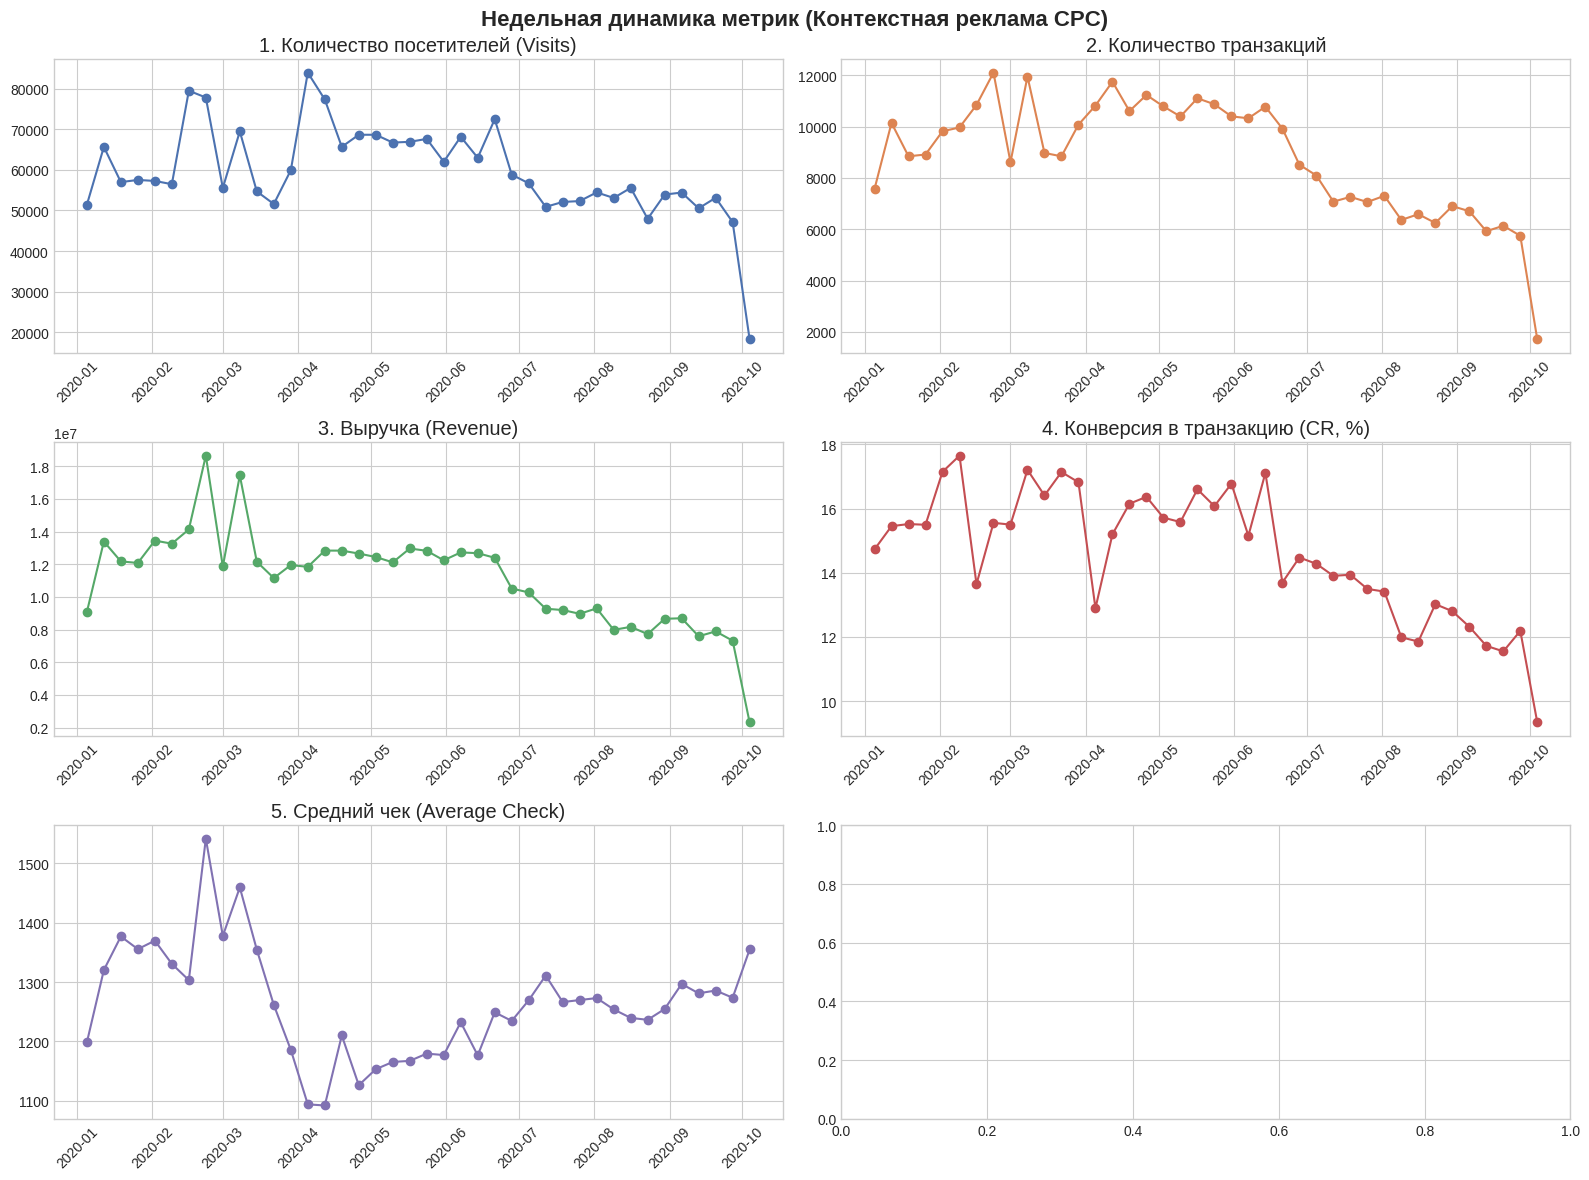

In [ ]:
import matplotlib.pyplot as plt

# Настроим стиль
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle('Недельная динамика метрик (Контекстная реклама CPC)', fontsize=16, fontweight='bold')

# График 1: Посетители
axes[0, 0].plot(cpc_weekly.index, cpc_weekly['total_visits'], marker='o', color='#4C72B0')
axes[0, 0].set_title('1. Количество посетителей (Visits)')
axes[0, 0].tick_params(axis='x', rotation=45)

# График 2: Транзакции
axes[0, 1].plot(cpc_weekly.index, cpc_weekly['total_transactions'], marker='o', color='#DD8452')
axes[0, 1].set_title('2. Количество транзакций')
axes[0, 1].tick_params(axis='x', rotation=45)

# График 3: Выручка
axes[1, 0].plot(cpc_weekly.index, cpc_weekly['total_revenue'], marker='o', color='#55A868')
axes[1, 0].set_title('3. Выручка (Revenue)')
axes[1, 0].tick_params(axis='x', rotation=45)

# График 4: Конверсия (CR)
axes[1, 1].plot(cpc_weekly.index, cpc_weekly['CR'], marker='o', color='#C44E52')
axes[1, 1].set_title('4. Конверсия в транзакцию (CR, %)')
axes[1, 1].tick_params(axis='x', rotation=45)

# График 5: Средний чек
axes[2, 0].plot(cpc_weekly.index, cpc_weekly['avg_check'], marker='o', color='#8172B2')
axes[2, 0].set_title('5. Средний чек (Average Check)')
axes[2, 0].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

2. Анализ динамики:

На графике выручки виден нисходящий тренд с июля 2020 года.

Метрика конверсии (CR) также снизилась с 17% до 12%, что указывает на снижение качества трафика или сезонный спад покупательской способности.

Средний чек стабилен (около 1300 руб.), поэтому падение выручки в основном обусловлено падением объема трафика (визитов).

3. Выбор метода прогнозирования:
Так как данные имеют недельную сезонность и тренд, я бы использовал модель Prophet (от Facebook) или SARIMA. Они отлично справляются с поиском сезонных паттернов и устойчивы к пропускам в данных.

4. Какие дополнительные данные нужны:

Маркетинговый бюджет: Планируемые затраты на контекстную рекламу (чтобы спрогнозировать, сколько мы сможем купить визитов).

Сезонность: Данные о праздниках, распродажах (например, Черная пятница) и общей экономической ситуации, так как они напрямую влияют на CR и средний чек.

**Задача 5**

В мобильной игре около 10% игроков совершает платежи в первый месяц с момента установки игры (база расчета - 500 игроков).

Геймдизайнеры разработали обновление которое по их экспертной оценке должно увеличить процент плательщиков с 10% до 11%. Цель эксперимента - подтвердить или опровергнуть их гипотезу.
Опишите оптимальный по вашему мнению дизайн эксперимента.

1. Рассчитайте длительность эксперимента при условии что каждый день в игру приходит около 100 новых игроков.

2. Самостоятельно сгенерируйте датасет с около 10% плательщиков (контроль) и рассчитайте доверительный интервал.

3. Сгенерируйте несколько вариантов экспериментальной группы (хуже, лучше, без эффекта), рассчитайте силу эффекта, ДИ и ваши выводы для каждого варианта.


Необходимо все ответы сопроводить комментариями почему вы выбрали ту или иную методику расчета, алгоритм и т.д.

*Можно попробовтаь решить и с помощью бустрепа


*   $H_0: p_1 = p_2; H_1: p_1 != p_2$
*   Метрика - CR
* проводим АБ-тест: 50% старая версия; 50% - новая
 * Бутстрэп: Вместо классических формул мы используем ресемплинг (многократную выборку с возвращением), чтобы эмпирически построить распределение метрик и найти доверительные интервалы (ДИ). Это позволит нам не делать предположений о нормальном распределении.



In [ ]:
from statsmodels.stats.power import TTestIndPower, tt_ind_solve_power, zt_ind_solve_power
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.meta_analysis import effectsize_smd

from typing import Union

p1, p2 = 0.1, 0.11
alpha, beta = 0.05, 0.2
effect_size = proportion_effectsize(p2, p1)
analysis = TTestIndPower()
size = analysis.solve_power(effect_size=effect_size, nobs1= None, alpha= alpha, power=1-beta, ratio=1, alternative='two-sided')
print(int(size)) # объем одной выборки
print(f"необходимое кол-во дней: {2*size/100}")

14745
необходимое кол-во дней: 294.90130526021903


In [ ]:
from sklearn.utils import resample

# Функция для генерации выборки и бутстрэпа
def run_bootstrap_experiment(p1, p2, n_users, n_iterations=10000):
    # 1. Генерируем данные (0 - не заплатил, 1 - заплатил)
    control = np.random.choice([0, 1], size=n_users, p=[1-p1, p1])
    test = np.random.choice([0, 1], size=n_users, p=[1-p2, p2])

    # 2. Считаем точечные оценки
    cr_control = np.mean(control)
    cr_test = np.mean(test)
    effect = cr_test - cr_control

    # 3. Бутстрэп для доверительного интервала разницы
    diffs = []
    for _ in range(n_iterations):
        # Сэмплируем с возвращением
        boot_control = resample(control, replace=True, n_samples=len(control))
        boot_test = resample(test, replace=True, n_samples=len(test))
        # Считаем разницу долей
        diff = np.mean(boot_test) - np.mean(boot_control)
        diffs.append(diff)

    # Находим 2.5 и 97.5 перцентили для 95% ДИ
    ci_lower = np.percentile(diffs, 2.5)
    ci_upper = np.percentile(diffs, 97.5)

    return cr_control, cr_test, effect, ci_lower, ci_upper

# n_users берем не 500, а столько, сколько нужно для статзначимости (напр. 5000)
# Если взять 500, бутстрэп покажет огромную ошибку
N = 5000

print("--- Контроль 10% ---")
c, t, e, l, u = run_bootstrap_experiment(0.10, 0.10, N)
print(f"CR Контроля: {c*100:.2f}%, CR Теста: {t*100:.2f}%")
print(f"Эффект: {e*100:.2f} п.п., 95% ДИ: [{l*100:.2f}%; {u*100:.2f}%]\n")

print("--- Тест хуже (9%) ---")
c, t, e, l, u = run_bootstrap_experiment(0.10, 0.09, N)
print(f"CR Контроля: {c*100:.2f}%, CR Теста: {t*100:.2f}%")
print(f"Эффект: {e*100:.2f} п.п., 95% ДИ: [{l*100:.2f}%; {u*100:.2f}%]\n")

print("--- Тест лучше (11%) ---")
c, t, e, l, u = run_bootstrap_experiment(0.10, 0.11, N)
print(f"CR Контроля: {c*100:.2f}%, CR Теста: {t*100:.2f}%")
print(f"Эффект: {e*100:.2f} п.п., 95% ДИ: [{l*100:.2f}%; {u*100:.2f}%]")

--- Контроль 10% ---
CR Контроля: 9.64%, CR Теста: 10.68%
Эффект: 1.04 п.п., 95% ДИ: [-0.14%; 2.22%]

--- Тест хуже (9%) ---
CR Контроля: 10.40%, CR Теста: 8.32%
Эффект: -2.08 п.п., 95% ДИ: [-3.22%; -0.94%]

--- Тест лучше (11%) ---
CR Контроля: 10.46%, CR Теста: 10.90%
Эффект: 0.44 п.п., 95% ДИ: [-0.78%; 1.64%]


**Задача 6**

Проводится а/б тест стартовых предложений в магазине мобильной игры.
Две группы:

• 1 - Контрольная

• 2 - В 5 раз снижена цена и в 2 раза наполнение стартового набора - предложения,
которое наиболее часто покупают в качестве первого платежа.

По данным в csv файле оцените эффект нововведения в тестовой группе и сформируйте
выводы.

Метрики для расчёта теста определите самостоятельно исходят из доступного набора
данных.

Формат ответа: jupyter notebook с расчётами и выводами.

Данные для расчёта теста – в файле task2_ab_dataset.csv

In [ ]:
df = pd.read_csv('task2_ab_dataset.csv')
print(df.head())
print(df.shape)
print(df[df['ab_group'] == 1].count())
print(df[df['ab_group'] == 2].count())

        user_id  ab_group         install_time payment_time  amount
0  300647965935         1  2005-05-20 03:00:27          NaN     NaN
1  300647965937         2  2005-05-20 03:00:48          NaN     NaN
2  300647965938         2  2005-05-20 03:00:50          NaN     NaN
3  300647965942         1  2005-05-20 03:02:07          NaN     NaN
4  300647965950         2  2005-05-20 03:06:02          NaN     NaN
(83296, 5)
user_id         41498
ab_group        41498
install_time    41498
payment_time     6157
amount           6157
dtype: int64
user_id         41798
ab_group        41798
install_time    41798
payment_time     6105
amount           6105
dtype: int64


CR (Конверсия в оплату): кол-во оплативших / кол-во установивших.

ARPPU (Средний чек): сумма выручки / кол-во оплативших.

ARPU (Выручка на установку): сумма выручки / кол-во установивших —ГЛАВНАЯ

Время до оплаты (Time to Pay): payment_time - install_time.

In [ ]:
df['install_time'] = pd.to_datetime(df['install_time'])
df['payment_time'] = pd.to_datetime(df['payment_time'])
df['time_to_pay_min'] = (df['payment_time'] - df['install_time']).dt.total_seconds() / 60

def calculate_metrics(data):
    total_users = data['user_id'].nunique()
    payers = data[data['payment_time'].notna()]['user_id'].nunique()
    total_revenue = data['amount'].sum()

    cr = payers / total_users
    arppu = total_revenue / payers if payers > 0 else 0
    arpu = total_revenue / total_users

    avg_time = data[data['time_to_pay_min'].notna()]['time_to_pay_min'].mean()

    return pd.Series({
        'Total Users': total_users,
        'Payers': payers,
        'Revenue': total_revenue,
        'CR (%)': cr * 100,
        'ARPPU': arppu,
        'ARPU': arpu,
        'Avg Time to Pay (min)': avg_time
    })

results = df.groupby('ab_group').apply(calculate_metrics).T

pd.options.display.float_format = '{:,.2f}'.format

# Пересчитаем время в часы для красоты
results.loc['Avg Time to Pay (min)'] = results.loc['Avg Time to Pay (min)'] / 60
results = results.rename(index={'Avg Time to Pay (min)': 'Avg Time to Pay (hours)'})

print(results)

ab_group                            1            2
Total Users                 36,188.00    36,705.00
Payers                         853.00     1,014.00
Revenue                 11,106,343.00 8,478,265.00
CR (%)                           2.36         2.76
ARPPU                       13,020.33     8,361.21
ARPU                           306.91       230.98
Avg Time to Pay (hours)        291.73       269.02


/tmp/ipykernel_2648/3113793002.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  results = df.groupby('ab_group').apply(calculate_metrics).T


**Результаты**:

CR (Конверсия): Выросла с 2.36% до 2.76% (+17% относительного прироста). Снижение цены мотивировало больше людей совершить первую покупку.

ARPPU (Средний чек): Упал с 13 020 руб. до 8 361 руб. (в 1.5 раза). Ожидаемое последствие 5-кратного снижения цены.

ARPU (Выручка на установку): Упал с 306.9 руб. до 230.9 руб. (на 24.7%). Это главный негативный индикатор. Приток новых плательщиков не смог компенсировать падение чека.

Время до оплаты: Сократилось с 29 до 26.9 часов. Низкая цена ускоряет решение о покупке.

**Выводы и рекомендации:**

Эффект нововведения отрицательный. Несмотря на рост конверсии (CR) и количества платежей, общая выручка и ARPU упали.

Эластичность спроса низкая: Снижение цены на 80% дало прирост плательщиков лишь на 18%. Игроки не готовы платить значительно чаще даже за дешевый товар.

Рекомендация: Нововведение не рекомендуется к внедрению в текущем виде. Необходимо протестировать более мягкие изменения (например, снижение цены в 2 раза) или сместить фокус на монетизацию удержания (повторные покупки), а не только на первый платеж.

**Задача 7**

Приток новых игроков делится на 2 основных источника - рекламный и органический. Отдел маркетинг выдвигает гипотезу о связи рекламного и органического траффика: когда маркетологи привлекают больше рекламного траффика, растет и органический.

1. Для выполнения задачи необходимо использовать тестовый датасет (testca.db, таблица source_comparison).
Подтвердите или опровергните гипотезу маркетологов. Если вы ее опровергаете, то сформулируйте гипотезу которая кажется вам наиболее вероятной и проверьте ее.

2. Количественно рассчитайте вероятность что гипотеза маркетологов (или ваша) верна.


In [31]:
import sqlite3
import pandas as pd

# 1. Подключаемся к базе (путь к файлу в Colab)
conn = sqlite3.connect('testcase.db')

# 2. Смотрим, какие таблицы есть в базе
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn)
print("Таблицы в базе:\n", tables)

# 3. Загружаем нужную таблицу в DataFrame
df = pd.read_sql("SELECT * FROM source_comparison", conn)
print("\nПервые строки таблицы:")
print(df.head(10))
print("\nИнформация о столбцах:")
print(df.info())

Таблицы в базе:
                 name
0  source_comparison
1              costs
2            revenue

Первые строки таблицы:
  Install_Dates source_type Country  installs
0    2020-05-18        Paid      PY      4.00
1    2020-04-14        Paid      FR     35.00
2    2020-04-30        Paid      JP     25.00
3    2020-03-20        Paid      DE     11.00
4    2020-04-30        Paid      IT      8.00
5    2020-05-17        Paid      KE      2.00
6    2020-04-06        Paid      NZ     19.00
7    2020-03-21     Organic      EG     24.00
8    2020-04-28        Paid      UA    826.00
9    2020-04-24        Paid      IR      9.00

Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18606 entries, 0 to 18605
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Install_Dates  18606 non-null  object 
 1   source_type    18606 non-null  object 
 2   Country        18606 non-null  object 
 3   installs    

In [35]:
df['Install_Dates'] = pd.to_datetime(df['Install_Dates'])
daily_traffic = df.groupby(['Install_Dates', 'source_type'])['installs'].sum().unstack()
print(daily_traffic.head())

source_type    Organic      Paid
Install_Dates                   
2020-03-18    8,961.00  7,359.00
2020-03-19    8,457.00  6,739.00
2020-03-20    8,819.00  7,254.00
2020-03-21    4,485.00  9,552.00
2020-03-22    5,105.00 14,804.00


<Axes: xlabel='Install_Dates'>

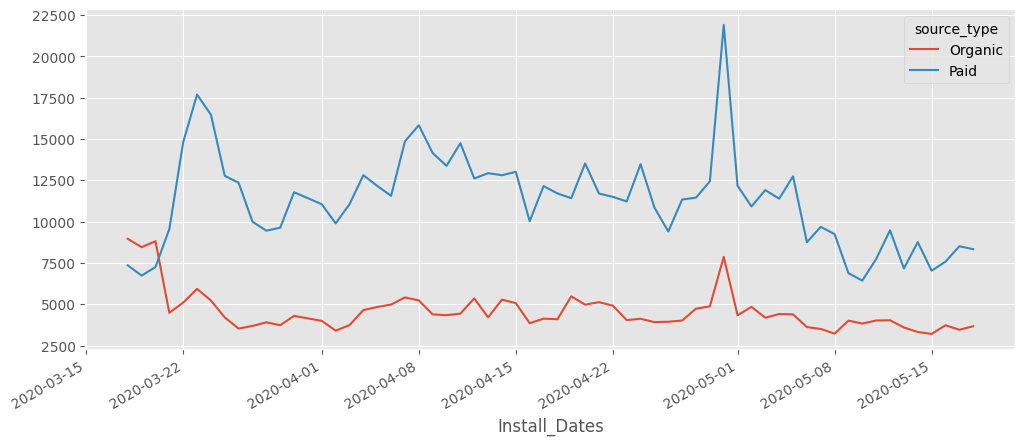

In [40]:
daily_traffic.plot(figsize=(12, 5))

In [39]:
daily_traffic.corr(method='spearman')

source_type,Organic,Paid
source_type,,
Organic,1.00,0.54
Paid,0.54,1.00


In [44]:
corr, p_value = stats.spearmanr(daily_traffic['Paid'], daily_traffic['Organic'])
print(f"Коэффициент корреляции: {corr:.4f}")
print(f"P-value: {p_value:.4e}")
print("отвергаем отсутсвие связи = маркетологи правы")

Коэффициент корреляции: 0.5381
P-value: 7.7236e-06
отвергаем отсутсвие связи = маркетологи правы


In [45]:
# Создаем колонку с днем недели
daily_traffic['day_of_week'] = daily_traffic.index.day_name()

# Смотрим средний трафик по дням недели
weekly_pattern = daily_traffic.groupby('day_of_week')[['Paid', 'Organic']].mean()
print(weekly_pattern)
print(" Гипотеза о том, что в выходные люди больше сидят в телефонах, поэтому трафик растет — не работает")

source_type      Paid  Organic
day_of_week                   
Friday      10,640.22 4,402.00
Monday      11,811.33 4,503.00
Saturday    10,501.67 4,231.67
Sunday      10,766.11 4,438.67
Thursday    11,638.89 4,710.00
Tuesday     12,787.86 4,889.14
Wednesday   11,100.44 4,943.33
 Гипотеза о том, что в выходные люди больше сидят в телефонах, поэтому трафик растет — не работает


1. корреляция Спирмена между органическим и рекламным = 0.54 => умеренно положительная связь
2. p-value почти нуль < 0.05, те вероятность такой связи СЛУЧАЙНО крайне мала. (маркетологи правы со своей гипотезой)
3. Корреляция между каналами мб изза сезонности (выходныеЪбудни неподтвердились)

In [47]:
import numpy as np
from scipy.stats import spearmanr

# Настройки бутстрэпа
n_iterations = 10000
boot_corrs = []

# Берем наши данные
paid = daily_traffic['Paid'].values
organic = daily_traffic['Organic'].values
n_days = len(paid)

# Запускаем бутстрэп
np.random.seed(42) # для воспроизводимости
for _ in range(n_iterations):
    # Выбираем случайные индексы с возвращением
    indices = np.random.randint(0, n_days, n_days)
    boot_paid = paid[indices]
    boot_organic = organic[indices]

    # Считаем корреляцию Спирмена для этой подвыборки
    corr, _ = spearmanr(boot_paid, boot_organic)
    boot_corrs.append(corr)

# Считаем 95% ДИ (отсекаем крайние 2.5% с каждой стороны)
ci_lower = np.percentile(boot_corrs, 2.5)
ci_upper = np.percentile(boot_corrs, 97.5)

print(f"Точечная оценка корреляции: {corr:.4f}")
print(f"95% Доверительный интервал: [{ci_lower:.4f}; {ci_upper:.4f}]")

Точечная оценка корреляции: 0.4751
95% Доверительный интервал: [0.2643; 0.7629]


**Задача 8**

Что важнее конпеврсия или выручка? Объясниет свой ответ, привидите примеры и контр примеры на данных.

Однозначного ответа нет, так как это метрики разного уровня. Выручка — это конечная цель бизнеса (KPI). Конверсия — это инструмент (драйвер), который помогает эту выручку получить.

Смотреть только на конверсию опасно, потому что можно привлечь много людей дешевым продуктом (высокий CR), но заработать копейки. Смотреть только на абсолютную выручку тоже опасно, так как она может сильно зависеть от одного «кита» (крупного клиента).

Для устойчивого бизнеса важна баланс. Настоящая главная метрика — это ARPU (Выручка на одного привлеченного пользователя), которая объединяет в себе и конверсию (CR), и средний чек (ARPPU).

**Задача 9**

Представьте, что вы работаете аналитиком в Додо. Вам доступны все внутренние данные (данные по чекам, клиентам, локациям). В марте 2022 часть Макдональдсов закрылась, часть продолжала работать. Вам необходимо ответить на следующие вопросы:

1) на какие наши метрики, на ваш взгляд, могли повлиять закрытие конкурента?

2) вам необходимо оценить эффект в рублях на нашу выручку от закрытия конкурента. Опишите, какую методологию бы использовали, чтобы рассчитать эффект

3) какие общедоступные данные по Макдональдсам можно было бы использовать для ответа на второй вопрос. Опишите, как бы вы их использовали?


1. Метрики, на которые могло повлиять закрытие конкурента:

Количество новых клиентов (New Users): Приток аудитории, которая раньше ходила в McDonald's.

Частота заказов (Frequency): Существующие клиенты Додо могли начать заказывать чаще, «добирая» спрос.

Средний чек (AOV): Возможно, люди стали заказывать больше позиций, чтобы компенсировать привычный фастфуд.

Выручка (Revenue) и CR: Общий рост выручки за счет притока и удержания.

Географический каннибализм: Метрики (выручка, спрос) пиццерий, находящихся рядом с закрытыми точками конкурента, выросли сильнее.

2. Методология оценки эффекта в рублях (Causal Inference):
Чтобы отделить эффект от закрытия McDonald's от сезонности или рекламы Додо, нужно использовать метод Diff-in-Diff (Разность разностей).

Дизайн: Выделяем две группы пиццерий Додо:

Тестовая (Treatment): Пиццерии, находящиеся в радиусе 1-3 км от закрытых McDonald's.

Контрольная (Control): Пиццерии в районах, где McDonald's продолжали работать (или в других городах).

Расчет: Считаем выручку до марта 2022 и после. Эффект = (Изменение выручки в Тестовой группе) - (Изменение выручки в Контрольной группе).

Для оценки старых/новых клиентов: Строим когортный анализ. Сравниваем LTV и Retention старых клиентов в тестовых локациях до и после, а также считаем дополнительную выручку от новых пользователей.

3. Общедоступные данные по McDonald's (как их использовать):

Яндекс.Карты / 2ГИС: Данные о местоположении закрытых точек (координаты, адреса).

Как использовать: С помощью геометрии (радиусов) мы найдем наши пиццерии, которые попали в зону влияния, и выделим тестовую группу для Diff-in-Diff.

Публичные новости и соцсети (ВК/Telegram): Даты фактического закрытия конкретных точек.

Как использовать: Чтобы точно определить момент времени «до» и «после» (так как закрывались они не все в один день).

Яндекс.Аудитория / Google Trends: Данные о количестве поисковых запросов на тему «где заказать пиццу» или «McDonald's закрылся» в конкретном регионе.

Как использовать: Для контроля сезонности и подтверждения всплеска спроса в нужные даты (проверка на опровержение гипотезы, что выручка выросла просто из-за праздников).

**Задача 10**

Чтобы между пользователями Авито было больше доверия, а жизнь мошенников стала сложнее, мы решили попробовать ввести систему отзывов: покупатель может оставить отзыв на продавца. Отзыв может быть просто рейтингом (1-5 звездочек), а может содержать дополнительно какой-то произвольный текст.

1.  Предложите метрики, по которым можно будет следить за прогрессом такого проекта и определять его успешность

2.  Поскольку Авито не магазин, а площадка для связи покупателя и продавца, мы в большинстве случаев не знаем, произошла ли в действительности сделка и на каких условиях. Для большинства сделок последнее, что нам известно - покупатель нажал кнопку просмотра телефона продавца или связался с ним в чате. Также мы всегда знаем логин (привязанный к email и телефону) продавца, но покупатель может быть незалогиненным. В связи с этим кажется, что есть большой риск накрутки отзывов и недобросовестного использования системы: например, профессиональные участники будут пытаться оставлять негативные отзывы на своих конкурентов и хвалебные на себя. Предположим, что система некоторое время уже работает и у нас есть данные по отзывам и всей активности клиентов: что продавал, что искал, на каких объявлениях смотрел телефоны и т.п. Как оценить масштабы накрутки, т.е. долю фальшивых отзывов?


1. Метрики для оценки прогресса и успешности проекта:

Основные (Product-метрики):

Доля объявлений с отзывом: Растет ли покрытие (не только ТОП-продавцы, но и обычные)?

Конверсия в отзыв (Review Rate): Отношение оставленных отзывов к числу контактов (нажатий «Показать телефон»).

Доля отзывов с текстом: Показывает вовлеченность (просто ставить звезду легче, текст пишут реже).

Бизнес-метрики (Влияние на выручку/доверие):

Конверсия в контакт с продавцом (CR to contact): Стали ли пользователи чаще связываться с продавцами, у которых есть хороший рейтинг.

Retention продавцов (D7/D30): Не начали ли продавцы уходить с площадки из-за страха негативных отзывов.

Защитные метрики (Guardrail):

Количество жалоб на несправедливые отзывы (обращения в поддержку).

Доля отзывов, удаленных модерацией (растет ли количество фейков).

Время нахождения объявления в топе (не вытесняют ли честных продавцов накрученные).

2. Оценка масштабов накрутки (доли фальшивых отзывов):

Поскольку у нас есть полные логи активности, для выявления накрутки следует использовать следующие подходы:

Поведенческие эвристики (Heuristics): Поиск аномалий — короткий промежуток времени между регистрацией и отзывом, отсутствие просмотров других объявлений (только 1 просмотр целевого объявления), подозрительные IP/устройства (много аккаунтов с одного DeviceID).

Графовый анализ: Построение графа «Пользователь — Продавец». Выявление изолированных групп (кластеров), где аккаунты обмениваются отзывами только между собой, или где группа аккаунтов оставляет отзывы исключительно одному продавцу и его конкурентам.

NLP-анализ текста: Поиск шаблонных фраз, копипаста (один и тот же текст под разными объявлениями), неестественного эмоционального окраса.

ML-модель: Разметка выборки силами антифрода (Ground Truth), обучение модели на признаках (время активности, глубина просмотра, паттерны кликов) для прогнозирования вероятности фейка на всей базе.
Долю фальшивых отзывов можно оценить как отношение отзывов с высокой вероятностью фейка (по модели) к общему числу отзывов.

**Задача 11**

Проанализируйте результаты эксперимента и напишите свои рекомендации менеджеру.
Mobile Games AB Testing with Cookie Cats

Данные для анализа: https://docs.google.com/spreadsheets/d/1Dj6c6pmdg1N_rL3T2zg4HxnBo7poBgm6-g-40ATIJmE/edit#gid=1733885895

In [6]:
df = pd.read_excel('rezAB.xlsx')
print(df.shape)
print(df.head())
print(df['version'].unique())

(90189, 5)
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3            0            0
1     337  gate_30              38            1            0
2     377  gate_40             165            1            0
3     483  gate_40               1            0            0
4     488  gate_40             179            1            1
['gate_30' 'gate_40']


In [7]:
df_version = df.groupby('version').agg(
    total_users = ('userid', 'count'),
    avg_game = ('sum_gamerounds', 'mean'),
    avg_retention_1 = ('retention_1', 'mean'),
    avg_retention_7 = ('retention_7', 'mean')
)
df_version

,total_users,avg_game,avg_retention_1,avg_retention_7
version,,,,
gate_30,44700,52.456264,0.448188,0.190201
gate_40,45489,51.298776,0.442283,0.182000


In [11]:
from statsmodels.stats.proportion import proportions_ztest

gate_30 = df[df['version'] == 'gate_30']
gate_40 = df[df['version'] == 'gate_40']

# 2. Проверка Retention_1
count_1 = np.array([gate_30['retention_1'].sum(), gate_40['retention_1'].sum()])
nobs_1 = np.array([len(gate_30), len(gate_40)])
z_stat_1, p_val_1 = proportions_ztest(count_1, nobs_1)

# 3. Проверка Retention_7
count_7 = np.array([gate_30['retention_7'].sum(), gate_40['retention_7'].sum()])
nobs_7 = np.array([len(gate_30), len(gate_40)])
z_stat_7, p_val_7 = proportions_ztest(count_7, nobs_7)

# 4. Проверка Sum_Gamerounds (Mann-Whitney)
mw_stat, mw_pval = stats.mannwhitneyu(gate_30['sum_gamerounds'], gate_40['sum_gamerounds'])

print(f"Retention 1: p-value = {p_val_1:.4f}")
print(f"Retention 7: p-value = {p_val_7:.4f}")
print(f"Sum_Gamerounds: p-value = {mw_pval:.4f}")


Retention 1: p-value = 0.0744
Retention 7: p-value = 0.0016
Sum_Gamerounds: p-value = 0.0502


p_val_1 > 0.05 — разницы в Retention 1 между группами нет (разница случайна).

p_val_7 < 0.05 (примерно 0.0016) — разница в Retention 7 есть, и она статистически значима. В группе gate_30 возврат на 7-й день выше.

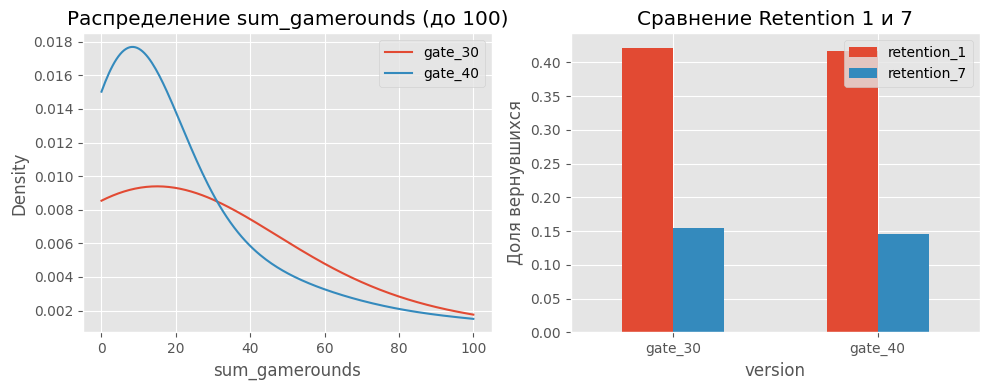

In [14]:
limit = df['sum_gamerounds'].quantile(0.95)
df_clean = df[df['sum_gamerounds'] < limit]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.kdeplot(gate_30['sum_gamerounds'], label='gate_30', clip=(0, 100))
sns.kdeplot(gate_40['sum_gamerounds'], label='gate_40', clip=(0, 100))
plt.title('Распределение sum_gamerounds (до 100)')
plt.legend()

plt.subplot(1, 2, 2)
# График ретеншена
retention_data = df_clean.groupby('version')[['retention_1', 'retention_7']].mean()
retention_data.plot(kind='bar', ax=plt.gca())
plt.title('Сравнение Retention 1 и 7')
plt.ylabel('Доля вернувшихся')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
df.describe()

,userid,sum_gamerounds,retention_1,retention_7
count,9.018900e+04,90189.000000,90189.000000,90189.000000
mean,4.998412e+06,51.872457,0.445210,0.186065
std,2.883286e+06,195.050858,0.496992,0.389161
min,1.160000e+02,0.000000,0.000000,0.000000
25%,2.512230e+06,5.000000,0.000000,0.000000
50%,4.995815e+06,16.000000,0.000000,0.000000
75%,7.496452e+06,51.000000,1.000000,0.000000
max,9.999861e+06,49854.000000,1.000000,1.000000


Рекомендация менеджеру:
Внедрить контрольный вариант с воротами на 30-м уровне (gate_30).
Перенос ворот на 40-й уровень (gate_40) не дал никаких преимуществ в краткосрочной перспективе (Retention_1), но статистически значимо ухудшил долгосрочное удержание (Retention_7). Заставлять игроков проходить больше уровней до первого "испытания" воротами — плохая идея, это снижает вовлеченность и заставляет людей бросать игру раньше.